# Agri-AI Bootcamp — Phase 1, Day 4
## Model Evaluation & Regularization

**Objective:** Demonstrate overfitting and underfitting, add manual L2 regularization to a NumPy regression model, and use GridSearchCV to choose Ridge `alpha` with cross-validation.

### Agriculture example
A drought year may be an unusual observation. Regularization penalizes overly large coefficients, potentially stabilizing a model. This is a demonstration using noisy synthetic weather/yield-like data; it is not a validated crop model.

**Important:** Tune hyperparameters on training data using cross-validation. Keep the final test set untouched until the end.


## 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, f1_score


## 2. Generate noisy weather-style data
We create a dataset with multiple features and noise, including a few drought-like outliers. This is synthetic data for illustrating regularization.

In [2]:
rng = np.random.default_rng(42)
n = 300

# Features: rainfall, temperature, fertilizer, soil moisture (illustrative units)
rainfall = rng.normal(600, 140, n)
temperature = rng.normal(28, 4, n)
fertilizer = rng.normal(90, 25, n)
soil_moisture = rng.normal(35, 8, n)

X = np.column_stack([rainfall, temperature, fertilizer, soil_moisture])

# Synthetic yield relationship plus noise
y = (0.004 * rainfall
     - 0.12 * temperature
     + 0.015 * fertilizer
     + 0.08 * soil_moisture
     + rng.normal(0, 1.8, n))

# A few drought-like anomalous observations
outlier_idx = rng.choice(n, size=8, replace=False)
y[outlier_idx] -= rng.uniform(5, 12, size=len(outlier_idx))

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (300, 4)
y shape: (300,)


## 3. Split data into training and final test set
Keep the test set separate. GridSearchCV will use only the training portion for cross-validation.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (240, 4) Test: (60, 4)


## 4. Manual L2 regularization in NumPy
For this section, standardize features using training statistics, then optimize weights and bias manually. The L2 penalty is applied to weights, not the intercept. Objective: MSE + lambda * sum(w²). Gradient for w includes `2 * lambda * w`; bias gradient is the MSE gradient only.

In [4]:
scaler_mean = X_train.mean(axis=0)
scaler_std = X_train.std(axis=0)
scaler_std[scaler_std == 0] = 1

X_train_scaled = (X_train - scaler_mean) / scaler_std
X_test_scaled = (X_test - scaler_mean) / scaler_std

def train_manual_l2(X, y, lam=0.1, lr=0.01, epochs=1000):
    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    b = 0.0
    losses = []

    for epoch in range(epochs):
        y_pred = X @ w + b
        error = y_pred - y

        mse = np.mean(error ** 2)
        penalty = lam * np.sum(w ** 2)
        total_loss = mse + penalty
        losses.append(total_loss)

        dw = (2 / n_samples) * (X.T @ error) + 2 * lam * w
        db = (2 / n_samples) * np.sum(error)

        w -= lr * dw
        b -= lr * db

    return w, b, losses

lambda_value = 0.1
w_l2, b_l2, loss_l2 = train_manual_l2(
    X_train_scaled, y_train, lam=lambda_value, lr=0.01, epochs=1000
)

print("Manual L2 weights:", w_l2)
print("Manual L2 bias:", b_l2)
print("Final objective:", loss_l2[-1])

Manual L2 weights: [ 0.54623402 -0.41360094  0.19539024  0.7219725 ]
Manual L2 bias: 2.8860985533848242
Final objective: 5.694080880677462


## 5. Plot manual L2 loss curve

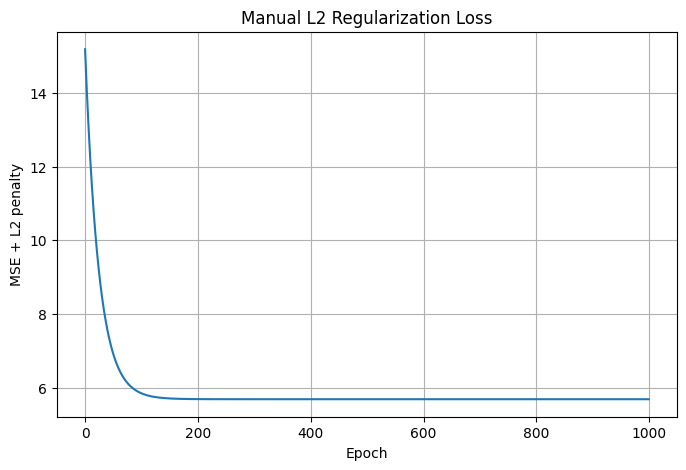

In [5]:
plt.figure(figsize=(8, 5))
plt.plot(loss_l2)
plt.xlabel("Epoch")
plt.ylabel("MSE + L2 penalty")
plt.title("Manual L2 Regularization Loss")
plt.grid(True)
plt.show()

## 6. Compare unregularized vs manual L2 weights

Unregularized weights: [ 0.60283523 -0.45137526  0.21674017  0.79126151]
L2 weights: [ 0.54623402 -0.41360094  0.19539024  0.7219725 ]


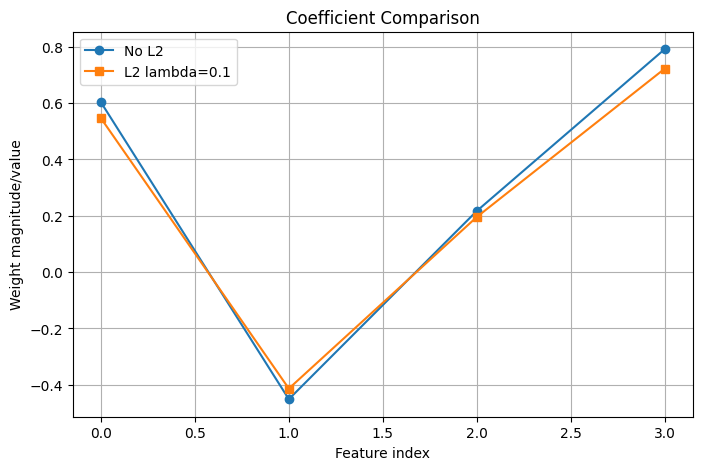

In [6]:
# Train unregularized model with the same gradient-descent implementation
w_unreg, b_unreg, loss_unreg = train_manual_l2(
    X_train_scaled, y_train, lam=0.0, lr=0.01, epochs=1000
)

print("Unregularized weights:", w_unreg)
print("L2 weights:", w_l2)

plt.figure(figsize=(8, 5))
positions = np.arange(len(w_l2))
plt.plot(positions, w_unreg, marker="o", label="No L2")
plt.plot(positions, w_l2, marker="s", label=f"L2 lambda={lambda_value}")
plt.xlabel("Feature index")
plt.ylabel("Weight magnitude/value")
plt.title("Coefficient Comparison")
plt.legend()
plt.grid(True)
plt.show()

## 7. GridSearchCV for Ridge alpha
Use a Pipeline so scaling is fitted inside each cross-validation fold, avoiding leakage. GridSearchCV evaluates the candidate alpha values using 5-fold CV on the training set only. `alpha` is the Ridge regularization strength (analogous to lambda; larger values penalize coefficients more strongly).

In [7]:
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

param_grid = {
    "ridge__alpha": [0.01, 0.1, 1, 10, 100]
}

gs = GridSearchCV(
    ridge_pipeline,
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    return_train_score=True
)

gs.fit(X_train, y_train)

print("Best parameters:", gs.best_params_)
print("Best CV MSE:", -gs.best_score_)

Best parameters: {'ridge__alpha': 1}
Best CV MSE: 5.7030286982514244


## 8. Visualize cross-validation scores by alpha

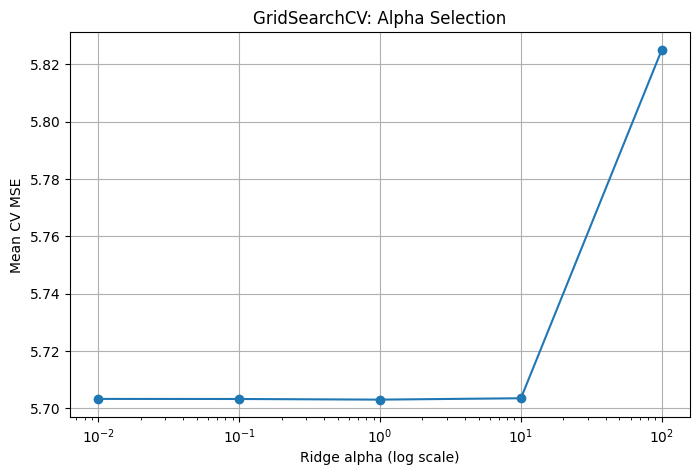

alpha=  0.01: CV MSE=5.7033
alpha=   0.1: CV MSE=5.7033
alpha=     1: CV MSE=5.7030
alpha=    10: CV MSE=5.7035
alpha=   100: CV MSE=5.8251


In [8]:
cv_results = gs.cv_results_
alphas = [0.01, 0.1, 1, 10, 100]
mean_cv_mse = -cv_results["mean_test_score"]

plt.figure(figsize=(8, 5))
plt.plot(alphas, mean_cv_mse, marker="o")
plt.xscale("log")
plt.xlabel("Ridge alpha (log scale)")
plt.ylabel("Mean CV MSE")
plt.title("GridSearchCV: Alpha Selection")
plt.grid(True)
plt.show()

for alpha, score in zip(alphas, mean_cv_mse):
    print(f"alpha={alpha:>6}: CV MSE={score:.4f}")

## 9. Final evaluation on held-out test set
Evaluate the selected model only once on the final test set after choosing alpha.

In [9]:
best_model = gs.best_estimator_
y_test_pred = best_model.predict(X_test)

test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)
test_mae = mean_absolute_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Test MSE:", test_mse)
print("Test RMSE:", test_rmse)
print("Test MAE:", test_mae)
print("Test R²:", test_r2)

Test MSE: 3.166118985121732
Test RMSE: 1.7793591501216757
Test MAE: 1.3835972167476358
Test R²: 0.28911129984028416


## 10. Demonstrate overfitting vs regularization (illustrative)
Compare test performance from the selected Ridge model to a high-degree polynomial model. The polynomial model may overfit this noisy synthetic dataset; scaling and polynomial expansion are kept inside pipelines.

In [10]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Use a single feature for the curve comparison (rainfall)
X1_train = X_train[:, [0]]
X1_test = X_test[:, [0]]

poly_model = Pipeline([
    ("poly", PolynomialFeatures(degree=12, include_bias=False)),
    ("scaler", StandardScaler()),
    ("linear", LinearRegression())
])
poly_model.fit(X1_train, y_train)
poly_pred = poly_model.predict(X1_test)
poly_test_mse = mean_squared_error(y_test, poly_pred)

print("Degree-12 polynomial test MSE:", poly_test_mse)
print("Selected Ridge test MSE:", test_mse)

Degree-12 polynomial test MSE: 9.953186640168497
Selected Ridge test MSE: 3.166118985121732


### Conclusion
Manual L2 regularization was added to the MSE objective and its gradient, shrinking coefficients. Ridge alpha was selected by 5-fold cross-validation on the training data using GridSearchCV. The final test set was reserved for evaluation. Results on synthetic weather-style data illustrate the workflow and should not be interpreted as agricultural findings.

